# 01. Data Understanding and Exploratory Data Analysis

## 1. Setup and Data Loading

This section imports the libraries used in the notebook and loads the dataset.

### 1.1 Importing Libraries

In [1]:
#necessary imports 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score, precision_score

### 1.2 Loading the Dataset

In [2]:
#loading the dataset
df = pd.read_csv("../data/zenodo_clean.csv")

## 2. Data Overview and Quality Checks
### 2.1 Previewing the Data

In [3]:
# first five rows 
df.head()

,student_id,gender,age,education,smoking,drinking,phq_total,phq_q1,phq_t1,phq_q2,...,pss_t13,pss_q14,pss_t14,avg_time_per_item,phq_severity,gad_severity,isi_severity,pss4_total,pss_helplessness,safety_flag
0,61739,female,21.0,bachelor's degree,never smokes,never drinks,2,1,5.54,0,...,1.94,2,5.74,2.53,minimal,minimal,none,3,7,0
1,61740,male,21.0,bachelor's degree,never smokes,never drinks,0,0,34.92,0,...,1.70,1,4.50,2.85,minimal,minimal,none,3,3,0
2,61741,male,22.0,bachelor's degree,never smokes,drinks occasionally (less than once a week),5,2,4.30,0,...,3.73,4,9.01,5.30,mild,minimal,none,8,12,0
3,61744,female,19.0,bachelor's degree,never smokes,drinks occasionally (less than once a week),2,0,2.23,0,...,2.48,1,3.57,2.79,minimal,minimal,none,0,3,0
4,61745,female,18.0,bachelor's degree,never smokes,never drinks,7,1,2.14,1,...,0.39,3,3.51,1.71,mild,mild,none,9,11,0


In [4]:
#last 5 rows
df.tail()

,student_id,gender,age,education,smoking,drinking,phq_total,phq_q1,phq_t1,phq_q2,...,pss_t13,pss_q14,pss_t14,avg_time_per_item,phq_severity,gad_severity,isi_severity,pss4_total,pss_helplessness,safety_flag
19246,86062,male,20.0,bachelor's degree,never smokes,never drinks,5,1,6.48,1,...,0.14,1,2.36,1.06,mild,minimal,none,8,1,0
19247,86063,male,19.0,bachelor's degree,never smokes,never drinks,2,0,5.19,1,...,3.88,1,4.23,3.12,minimal,minimal,none,3,5,0
19248,86064,female,21.0,bachelor's degree,never smokes,drinks occasionally (less than once a week),5,1,7.03,1,...,6.43,2,4.33,4.64,mild,minimal,none,7,8,0
19249,86065,male,21.0,bachelor's degree,current smoker (cumulative smoking >10 packs),current regular drinker (more than once a week),6,1,9.06,1,...,3.33,3,6.70,7.14,mild,minimal,none,7,14,0
19250,101218,female,18.0,bachelor's degree,never smokes,drinks occasionally (less than once a week),3,1,11.70,0,...,0.08,1,1.56,2.13,minimal,minimal,none,8,0,0


### 2.2 Dimensions and Data Types

In [5]:
#shape of the dataset
df.shape

(19251, 91)

In [6]:
#column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19251 entries, 0 to 19250
Data columns (total 91 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   student_id         19251 non-null  int64  
 1   gender             19251 non-null  str    
 2   age                19251 non-null  float64
 3   education          19251 non-null  str    
 4   smoking            19251 non-null  str    
 5   drinking           19251 non-null  str    
 6   phq_total          19251 non-null  int64  
 7   phq_q1             19251 non-null  int64  
 8   phq_t1             19251 non-null  float64
 9   phq_q2             19251 non-null  int64  
 10  phq_t2             19251 non-null  float64
 11  phq_q3             19251 non-null  int64  
 12  phq_t3             19251 non-null  float64
 13  phq_q4             19251 non-null  int64  
 14  phq_t4             19251 non-null  float64
 15  phq_q5             19251 non-null  int64  
 16  phq_t5             19251 non-null

### 2.3 Missing Values and Duplicates

In [7]:
#checking for missing values
df.isnull().sum().sum()

np.int64(0)

In [8]:
#checking for duplicates
df.duplicated().sum()

np.int64(0)

### 2.4 Summary Statistics of the Main Scores

In [9]:
#summary statistics for the main scores
df[['age', 'phq_total', 'gad_total', 'isi_total', 'pss_total']].describe()

,age,phq_total,gad_total,isi_total,pss_total
count,19251.000000,19251.000000,19251.000000,19251.000000,19251.000000
mean,20.576022,4.064049,2.374526,3.434731,20.962340
std,1.980653,3.687184,3.062498,3.499928,7.682389
min,16.000000,0.000000,0.000000,0.000000,0.000000
25%,19.000000,1.000000,0.000000,1.000000,15.000000
50%,20.000000,3.000000,1.000000,2.000000,21.000000
75%,22.000000,6.000000,4.000000,5.000000,27.000000
max,35.000000,27.000000,21.000000,28.000000,56.000000


### 2.5 Categorical Variables

In [10]:
#looking at the categorical columns
print(df['gender'].value_counts())
print(df['education'].value_counts())
print(df['smoking'].value_counts())
print(df['drinking'].value_counts())

gender
female    12691
male       6560
Name: count, dtype: int64
education
bachelor's degree    17717
associate degree      1041
master's degree        474
doctorate degree        19
Name: count, dtype: int64
smoking
never smokes                                                              17796
occasional smoker (cumulative smoking <10 packs)                            856
current smoker (cumulative smoking >10 packs)                               448
former smoker (cumulative smoking >10 packs), but not in the past year      151
Name: count, dtype: int64
drinking
never drinks                                                           12574
drinks occasionally (less than once a week)                             6238
drank in the past (more than once a week), but not in the past year      247
current regular drinker (more than once a week)                          192
Name: count, dtype: int64


## 3. Target Variable Definition

The model predicts a yes/no outcome, so the PHQ-9 total has to be converted into a label. A PHQ-9 total of 10 or more is the conventional threshold for moderate or worse depression. The standard severity bands are 0 to 4 minimal, 5 to 9 mild, 10 to 14 moderate, 15 to 19 moderately severe and 20 to 27 severe. 

### 3.1 Creating the Binary Target

The new column `depressed` is 1 when `phq_total >= 10` and 0 otherwise. The next two cells count the students in each class and express the counts as percentages.

In [11]:
#creating the target column
df['depressed'] = (df['phq_total'] >= 10).astype(int)
df['depressed'].value_counts()

depressed
0    17967
1     1284
Name: count, dtype: int64

In [12]:
#percentage of depressed vs not depressed
df['depressed'].value_counts(normalize=True) * 100

depressed
0    93.330217
1     6.669783
Name: proportion, dtype: float64

### 3.2 Creating the Three Screening Levels

The app gives one of three results, so a second target column `level` is created from the standard PHQ-9 bands: 0 = okay (0 to 4), 1 = mild (5 to 9) and 2 = moderate or worse (10 to 27). Level 2 is the same group as `depressed = 1`, so the binary column is kept for the EDA below.

In [13]:
#creating the three levels: 0 = okay, 1 = mild, 2 = moderate or worse
df['level'] = pd.cut(df['phq_total'], bins=[-1, 4, 9, 27], labels=[0, 1, 2]).astype(int)
df['level'].value_counts().sort_index()

level
0    11933
1     6034
2     1284
Name: count, dtype: int64

In [14]:
#percentage in each level
df['level'].value_counts(normalize=True).sort_index() * 100

level
0    61.986390
1    31.343826
2     6.669783
Name: proportion, dtype: float64

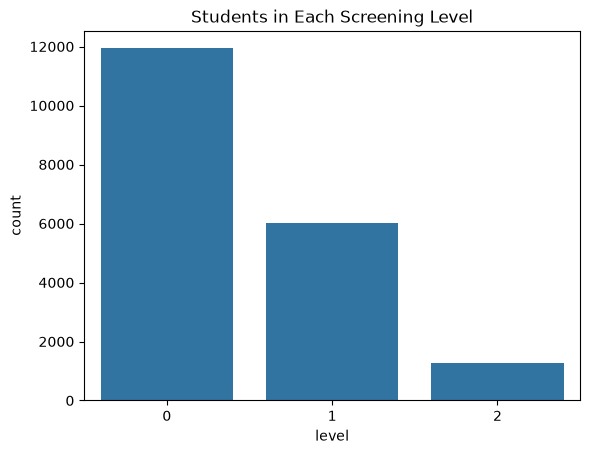

In [15]:
#visualising the three levels
sns.countplot(x='level', data=df)
plt.title('Students in Each Screening Level')
plt.show()

#### Observation

62.0% of students are okay (11,933), 31.3% are mild (6,034) and 6.7% are moderate or worse (1,284). The mild group is large enough to learn from, but level 2 is still a small minority, so recall on level 2 remains the main metric, and stratified splits and class weights are still needed.

### 3.3 Visualising the Class Balance

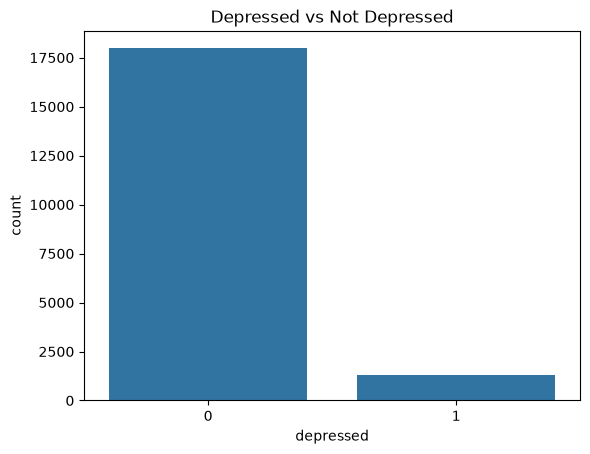

In [16]:
#visualising the target
sns.countplot(x='depressed', data=df)
plt.title('Depressed vs Not Depressed')
plt.show()

#### Observation

The bar for non-depressed students is about fourteen times taller than the bar for depressed students (17,967 against 1,284, roughly 93% against 7%), so this is a strongly imbalanced problem. A model that labelled every student as not depressed would be 93.3% accurate while detecting no depressed students at all, which is why accuracy alone is misleading here. For a screening tool a missed case is more costly than a false alarm, so recall (the share of depressed students who are identified) is the main metric, supported by precision and the precision-recall curve. The imbalance will be handled during modelling, for example with stratified train-test splits and class weights.

## 4. Exploratory Data Analysis

This section examines how PHQ-9 scores are distributed, how depression relates to gender and drinking, how anxiety, insomnia and stress differ between depressed and non-depressed students, and which individual questions are most related to PHQ-9. It ends with the PHQ-2 baseline. The aim is to understand the data and guide feature selection. The relationships found are associations and do not establish causes.

### 4.1 Distribution of PHQ-9 Total Scores

The histogram shows one bar for each possible PHQ-9 total (0 to 27), and the dashed red line marks the cut-off of 10. It shows how the continuous score relates to the binary target.

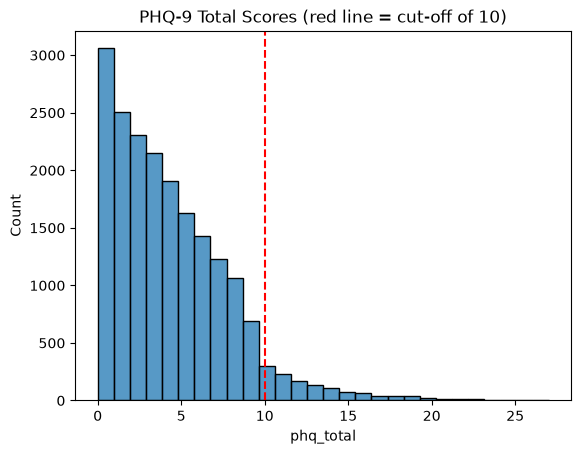

In [17]:
#distribution of phq-9 total scores
sns.histplot(df['phq_total'], bins=28)
plt.axvline(10, color='red', linestyle='--')
plt.title('PHQ-9 Total Scores (red line = cut-off of 10)')
plt.show()

#### Observation

The distribution is strongly right-skewed. The most common score is 0 (3,058 students), counts fall steadily as scores rise, and 70.5% of students score 5 or less. Only 304 students score exactly 10, compared with 688 who score 9, so the cut-off sits at the start of a long, thin tail and not at a natural gap in the data. Students on either side of the line have very similar symptom levels, so borderline cases will be the hardest for any model to classify. Scores of 20 or more are rare (87 students).

### 4.2 Depression Rate by Gender

The bar height is the proportion of students in each gender with `depressed = 1` (0.07 means 7%), and the black lines are 95% confidence intervals calculated by seaborn. This checks whether gender is related to the outcome.

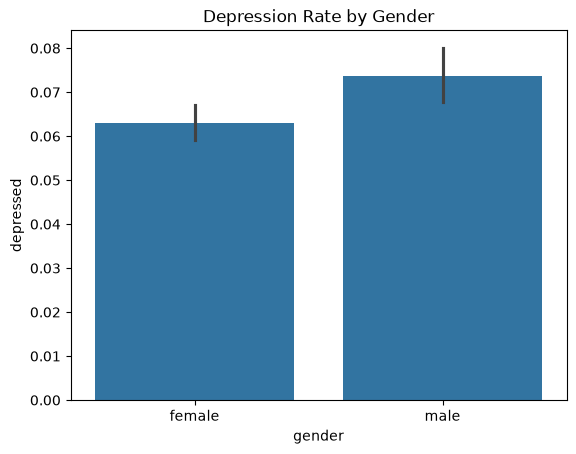

In [18]:
#depression rate by gender
df.groupby('gender')['depressed'].mean() * 100
sns.barplot(x='gender', y='depressed', data=df)
plt.title('Depression Rate by Gender')
plt.show()

#### Observation

About 6.3% of female students (800 of 12,691) and 7.4% of male students (484 of 6,560) are at or above the cut-off. The gap is roughly one percentage point, and both rates are close to the overall 6.67%, so gender separates depressed from non-depressed students only weakly. This is an association in this sample and does not explain why the rates differ. Men are the smaller group (34% of students), so their rate is estimated less precisely. Gender is unlikely to drive the model's predictions.

### 4.3 Depression Rate by Drinking Habits

The cell calculates the percentage of depressed students in each drinking category. A table is used instead of a plot because the category labels are long.

In [19]:
#depression rate by drinking habits
df.groupby('drinking')['depressed'].mean() * 100

drinking
current regular drinker (more than once a week)                        28.125000
drank in the past (more than once a week), but not in the past year    11.740891
drinks occasionally (less than once a week)                             9.410067
never drinks                                                            4.883092
Name: depressed, dtype: float64

#### Observation

The depression rate rises with drinking frequency: 4.9% among students who never drink, 9.4% among occasional drinkers, 11.7% among those who drank regularly in the past, and 28.1% among current regular drinkers (54 of 192), nearly six times the rate of non-drinkers. This is an association and not evidence that drinking causes depression. Students may drink to cope with low mood, and other factors may influence both. The highest-risk groups are small, and 1,201 of the 1,284 depressed students (93.5%) are non-drinkers or occasional drinkers, so drinking cannot identify most cases and is at best a weak supporting feature.

### 4.4 Depression Rate by Education Level

The cell calculates the percentage of depressed students at each education level. 

In [20]:
#depression rate by education level
df.groupby('education')['depressed'].mean() * 100

education
associate degree      8.261287
bachelor's degree     6.564317
doctorate degree     10.526316
master's degree       6.962025
Name: depressed, dtype: float64

In [21]:
#number of students in each education level
df['education'].value_counts()

education
bachelor's degree    17717
associate degree      1041
master's degree        474
doctorate degree        19
Name: count, dtype: int64

#### Observation

The depression rate is 8.3% among associate-degree students (86 of 1,041), 6.6% among bachelor's students (1,163 of 17,717), 7.0% among master's students (33 of 474) and 10.5% among doctorate students (2 of 19). Associate-degree students are slightly higher than bachelor's students, which is the opposite of the idea that degree students are more stressed. The gaps are small, and the doctorate group is too small to draw conclusions from (19 students). Bachelor's students make up 92% of the sample, so education level separates depressed from non-depressed students only weakly.

### 4.5 Depression Rate by Smoking Habits

The cell calculates the percentage of depressed students in each smoking category.

In [22]:
#depression rate by smoking habits
df.groupby('smoking')['depressed'].mean() * 100

smoking
current smoker (cumulative smoking >10 packs)                             18.303571
former smoker (cumulative smoking >10 packs), but not in the past year    18.543046
never smokes                                                               6.063160
occasional smoker (cumulative smoking <10 packs)                          11.098131
Name: depressed, dtype: float64

#### Observation

The depression rate is 6.1% among students who never smoke, 11.1% among occasional smokers, 18.3% among current smokers (82 of 448) and 18.5% among former smokers (28 of 151). Smokers have roughly three times the rate of non-smokers. As with drinking, this is an association and not evidence that smoking causes depression. The smoking groups are small, and 1,079 of the 1,284 depressed students (84%) have never smoked, so smoking cannot identify most cases and is at best a weak supporting feature.

### 4.6 Age and Depression

The boxplot compares the ages of non-depressed (0) and depressed (1) students. The ages are then grouped into bands so the depression rate can be compared across the bands.

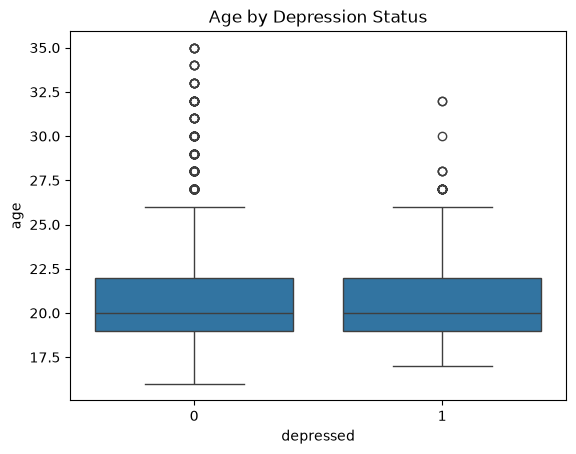

In [23]:
#comparing age between the two groups
sns.boxplot(x='depressed', y='age', data=df)
plt.title('Age by Depression Status')
plt.show()

In [24]:
#putting ages into groups
df['age_group'] = pd.cut(df['age'], bins=[15, 18, 20, 22, 25, 35], labels=['16-18', '19-20', '21-22', '23-25', '26-35'])
df['age_group'].value_counts()

age_group
19-20    8351
21-22    5789
23-25    2475
16-18    2301
26-35     335
Name: count, dtype: int64

In [25]:
#depression rate by age group
df.groupby('age_group')['depressed'].mean() * 100

age_group
16-18    5.302043
19-20    6.586038
21-22    6.996027
23-25    7.030303
26-35    9.850746
Name: depressed, dtype: float64

#### Observation

The two groups have almost the same ages. The mean age is 20.7 for depressed students and 20.6 for non-depressed students, and both groups have a median of 20. By age band, the depression rate rises gently from 5.3% (16-18) to 6.6% (19-20), 7.0% (21-22) and 7.0% (23-25), and reaches 9.9% for ages 26-35. The oldest band is small (335 students), so its higher rate is less reliable. Age is only weakly related to depression in this sample and is unlikely to drive the model's predictions.

### 4.7 Anxiety, Insomnia and Stress by Depression Status

The boxplots compare GAD-7 (anxiety), ISI (insomnia) and PSS (perceived stress) totals between non-depressed (0) and depressed (1) students. If the scores differ clearly between the groups, these questionnaires are useful for predicting depression and could replace the PHQ-9 items that cannot be used.

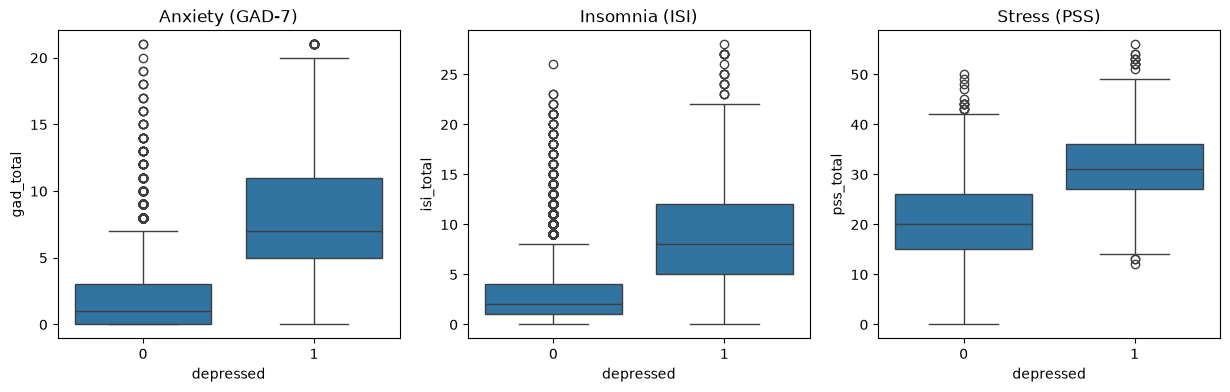

In [26]:
#comparing anxiety, insomnia and stress scores between the two groups
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x='depressed', y='gad_total', data=df, ax=ax[0])
sns.boxplot(x='depressed', y='isi_total', data=df, ax=ax[1])
sns.boxplot(x='depressed', y='pss_total', data=df, ax=ax[2])
ax[0].set_title('Anxiety (GAD-7)')
ax[1].set_title('Insomnia (ISI)')
ax[2].set_title('Stress (PSS)')
plt.show()

#### Observation

Depressed students score clearly higher on all three scales. Median anxiety is 7 against 1, median insomnia is 8 against 2 and median stress is 31 against 20 (means 8.2 against 2.0, 9.0 against 3.0 and 31.8 against 20.2). On each scale the lower quartile of the depressed group (5, 5 and 27) is above the upper quartile of the non-depressed group (3, 4 and 26). The groups still overlap: the non-depressed group has many high-scoring outliers, and about 19% of depressed students score below 5 on GAD-7. No single scale is enough on its own, which is why the model will combine several questions.

### 4.5 Correlations Between Questionnaire Totals

The heatmap shows the Pearson correlation between the four questionnaire totals, from -1 to 1. It shows how closely the scales move together. This matters for logistic regression because strongly correlated predictors carry overlapping information.

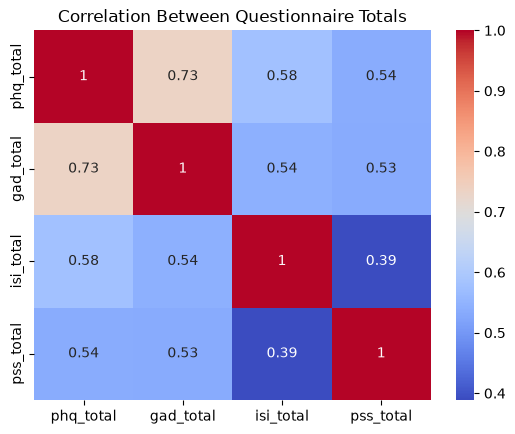

In [27]:
#correlation heatmap of the four totals
sns.heatmap(df[['phq_total', 'gad_total', 'isi_total', 'pss_total']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Between Questionnaire Totals')
plt.show()

#### Observation

All four totals are positively correlated. PHQ-9 correlates most strongly with GAD-7 (0.73) and moderately with ISI (0.58) and PSS (0.54), while the correlations among the other three are 0.54 (GAD-7 and ISI), 0.53 (GAD-7 and PSS) and 0.39 (ISI and PSS). This fits the common co-occurrence of depression, anxiety, poor sleep and stress, and explains why items from the other questionnaires can help predict PHQ-9. No pair is above 0.73, so the scales are related but not interchangeable, and each adds some separate information. Overlap between predictors should be checked again at item level when the features are selected.

### 4.6 Individual Questions and PHQ-9

To decide which questions should go into the screening app, each candidate item is correlated with the PHQ-9 total. The candidates are PHQ-9 items 1 and 2, all seven GAD-7 items, all seven ISI items and all 14 PSS items. PHQ-9 items 3 to 9 are left out because they make up the target (see Section 3.3). The bar chart ranks the items from strongest to weakest correlation.

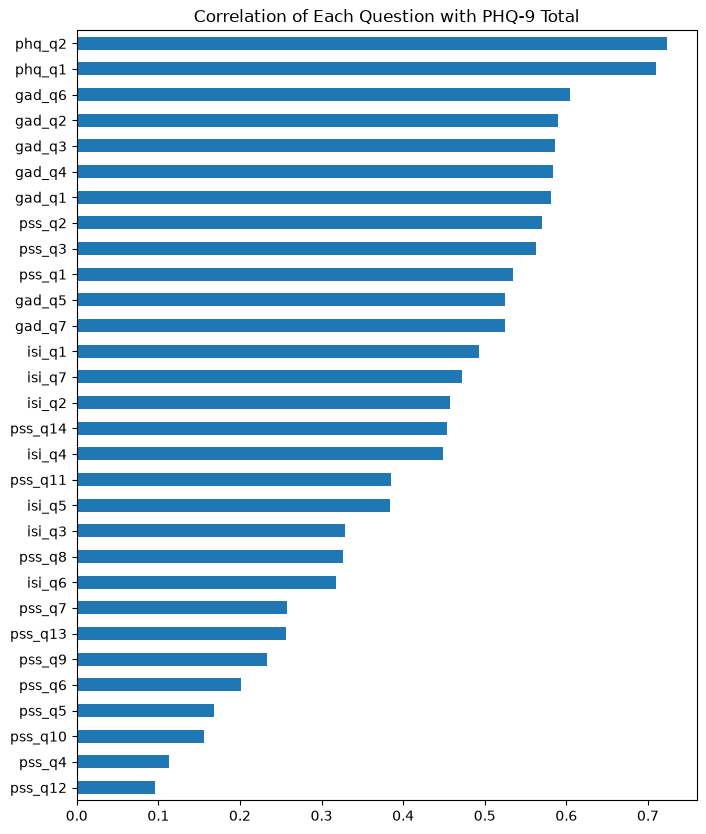

In [28]:
#questions we are allowed to use (phq q3-q9 are left out because they make up the answer)
phq_items = ['phq_q1', 'phq_q2']
gad_items = ['gad_q1', 'gad_q2', 'gad_q3', 'gad_q4', 'gad_q5', 'gad_q6', 'gad_q7']
isi_items = ['isi_q1', 'isi_q2', 'isi_q3', 'isi_q4', 'isi_q5', 'isi_q6', 'isi_q7']
pss_items = ['pss_q1', 'pss_q2', 'pss_q3', 'pss_q4', 'pss_q5', 'pss_q6', 'pss_q7', 'pss_q8', 'pss_q9', 'pss_q10', 'pss_q11', 'pss_q12', 'pss_q13', 'pss_q14']
items = phq_items + gad_items + isi_items + pss_items

corr = df[items + ['phq_total']].corr()['phq_total'].drop('phq_total').sort_values(ascending=False)
corr

corr.plot(kind='barh', figsize=(8, 10))
plt.title('Correlation of Each Question with PHQ-9 Total')
plt.gca().invert_yaxis()
plt.show()

#### Observation

`phq_q2` (0.72) and `phq_q1` (0.71) correlate most strongly with the PHQ-9 total, followed by the GAD-7 items (about 0.53 to 0.60, highest `gad_q6`), three PSS items (`pss_q2` 0.57, `pss_q3` 0.56, `pss_q1` 0.53) and the ISI items (0.32 to 0.49, highest `isi_q1`). Many PSS items are weak, with `pss_q12` (0.10), `pss_q4` (0.11) and `pss_q10` (0.16) at the bottom. This supports a short questionnaire built from the two PHQ-2 questions plus a few of the strongest GAD-7, PSS and ISI items, instead of all 30 candidates, since the weak items add length without much signal. Two cautions apply: `phq_q1` and `phq_q2` are part of the PHQ-9 total, so some of their correlation is built in, and items are assessed one at a time, so items from the same questionnaire partly overlap. The selection itself is made in `02_preprocessing.ipynb`, and the coefficients of the fitted model in `03_logistic_regression.ipynb` show which questions the model actually relies on.

### 4.7 PHQ-2 Baseline

The PHQ-2 is the sum of the first two PHQ-9 questions, and a score of 3 or more is the standard rule for a positive screen. The new `phq2` column is used for this comparison. The crosstab compares the rule (rows: False means a score below 3, True means 3 or more) with the true label (columns: 0 means not depressed, 1 means depressed). It sets the baseline that the model has to beat.

In [29]:
#phq-2 score = first two phq questions
df['phq2'] = df['phq_q1'] + df['phq_q2']

#phq-2 rule: score of 3 or more = possible depression
pd.crosstab(df['phq2'] >= 3, df['depressed'])

depressed,0,1
phq2,,
False,17467,472
True,500,812


#### Interpretation

The PHQ-2 rule flags 1,312 students (6.8% of the sample). It catches 812 of the 1,284 depressed students (recall 63.2%) and misses 472 (36.8%), and it wrongly flags 500 non-depressed students (precision 61.9%, specificity 97.2%). Its overall accuracy is 95.0%, only about 1.6 percentage points above the 93.3% obtained by labelling everyone as not depressed, which again shows why accuracy is a poor measure here. This is the baseline for the project: the model needs to find more of the 472 missed students, with recall above 63%, without a large rise in false alarms.

### 4.8 Summary of EDA Findings

- Data quality: The dataset has 19,251 students and 91 columns with no missing values or duplicate rows. The sample is young (mean age 20.6), mostly female (65.9%) and mostly undergraduate (92.0%), so results should be generalised with care.
- Class imbalance: Only 1,284 students (6.67%) have a PHQ-9 total of 10 or more. Accuracy is misleading (always predicting "not depressed" gives 93.3%), so recall is the priority metric, and the modelling will use stratified splits and class weights.
- PHQ-9 distribution: Scores are strongly right-skewed with a mode of 0. The cut-off of 10 falls in the tail (688 students score 9 and 304 score 10), so borderline cases will be difficult to classify.
- Demographics and lifestyle: Gender differs little (6.3% for women, 7.4% for men). Depression rates rise with drinking, from 4.9% for non-drinkers to 28.1% for current regular drinkers, but this is an association only, the highest-risk groups are small, and most depressed students drink little or not at all. Smoking shows a stronger association (6.1% for non-smokers against about 18% for current and former smokers), but smokers are a small group.
- Education and age differ little (rates of 6.6% to 8.3% across the main education levels, and 5.3% to 7.0% for ages 16 to 25)
- Related questionnaires: Depressed students have higher anxiety, insomnia and stress scores (median GAD-7 7 against 1, ISI 8 against 2, PSS 31 against 20). The totals correlate with PHQ-9 at 0.73 (GAD-7), 0.58 (ISI) and 0.54 (PSS), but the groups overlap, so several questions will be combined.
- Candidate questions: The two PHQ-2 questions (0.71 and 0.72), the GAD-7 items and a few PSS and ISI items correlate most with PHQ-9, while many PSS items are weak. This supports a short questionnaire. `phq_total`, `phq_severity`, `safety_flag` and `phq_q3` to `phq_q9` are excluded to avoid data leakage.
- Baseline to beat: The PHQ-2 rule catches 812 of 1,284 depressed students (recall 63.2%), misses 472 and raises 500 false alarms. The logistic regression model will be judged mainly on whether it improves recall over this baseline at an acceptable false-alarm rate.

The next notebook, `02_preprocessing.ipynb`, selects the features and creates the training and test sets.